<a href="https://colab.research.google.com/github/seanyi-creator/ba-305-project/blob/main/01_permit_data_overview.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Team A7 - Permit Dataset Overview
A look at the raw SF building permits data and the logic behind each cleaning step. We explored the data here, to decide which permits to keep, which columns to drop and which features to build. Those decisions are then packaged into permits_data.py, so the model notebooks (logistic regression, decision tree and random forest, neural network) can load the same cleaned dataset with a single function call instead of repeating the cleaning code.

In [1]:
# --- setup ---
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 50)

# In Colab the file isn't there yet, so download it from the team GitHub repo first.
if not os.path.exists('permits_data.py'):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/seanyi-creator/ba-305-project/main/permits_data.py',
        'permits_data.py')

from permits_data import (load_permits, resolved_permits, add_features, batch_id, get_permit_data,
                          make_preprocessor, FINAL_STATUS, NUMERIC, CATEGORICAL)

## 1. Raw data

In [2]:
raw = load_permits()
print(f'{raw.shape[0]:,} rows × {raw.shape[1]} columns')
raw.head()

86,103 rows × 44 columns


,permit_number,permit_type,permit_type_definition,permit_creation_date,block,lot,street_number,street_number_suffix,street_name,street_suffix,unit,unit_suffix,description,status,status_date,filed_date,issued_date,completed_date,first_construction_document_date,structural_notification,number_of_existing_stories,number_of_proposed_stories,voluntary_soft_story_retrofit,fire_only_permit,permit_expiration_date,estimated_cost,revised_cost,existing_use,existing_units,proposed_use,proposed_units,plansets,tidf_compliance,existing_construction_type,existing_construction_type_description,proposed_construction_type,proposed_construction_type_description,site_permit,supervisor_district,neighborhoods_analysis_boundaries,zipcode,location,record_id,date
0,2000010368,3,additions alterations or repairs,2000-01-03T00:00:00Z,0113,025,9,NaN,Calhoun,Tr,NaN,NaN,convert 3unit into 2unit convert garage into l...,complete,2003-01-23T00:00:00Z,2000-01-03T00:00:00Z,2001-03-02T00:00:00Z,2003-01-23T00:00:00Z,NaN,NaN,2.0,2.0,NaN,NaN,2003-03-02T00:00:00Z,180000.0,480000.0,apartments,3.0,2 family dwelling,2.0,2.0,NaN,5.0,wood frame (5),5.0,wood frame (5),NaN,3.0,North Beach,94133.0,POINT (-122.40378074667099 37.80076017854741),76172259173,2000-01-03
1,2000010353,6,demolitions,2000-01-03T00:00:00Z,1785,001A,2921,NaN,Irving,St,NaN,NaN,demolish old barn building,complete,2000-06-21T00:00:00Z,2000-01-03T00:00:00Z,2000-04-06T00:00:00Z,2000-06-21T00:00:00Z,NaN,NaN,1.0,NaN,NaN,NaN,2000-10-03T00:00:00Z,NaN,NaN,storage shed,0.0,NaN,NaN,0.0,NaN,5.0,wood frame (5),NaN,NaN,NaN,4.0,Sunset/Parkside,94122.0,POINT (-122.48934486192445 37.76277580044787),761712114087,2000-01-03
2,2000010498,3,additions alterations or repairs,2000-01-04T00:00:00Z,3705,042,865,NaN,Market,St,NaN,NaN,one stop project tenant improvment at 865 mark...,complete,2000-02-23T00:00:00Z,2000-01-04T00:00:00Z,2000-02-02T00:00:00Z,2000-02-23T00:00:00Z,NaN,NaN,5.0,5.0,NaN,NaN,2002-02-02T00:00:00Z,317000.0,NaN,retail sales,0.0,retail sales,0.0,4.0,NaN,2.0,constr type 2,2.0,constr type 2,NaN,6.0,South of Market,94103.0,POINT (-122.40715841875158 37.783946952773675),761798164435,2000-01-04
3,2000010484,3,additions alterations or repairs,2000-01-04T00:00:00Z,6540,040,525,NaN,Jersey,St,NaN,NaN,"enclosing roof terrace, remodeling bedrooms an...",expired,2001-09-17T00:00:00Z,2000-01-04T00:00:00Z,2000-08-08T00:00:00Z,NaN,2000-08-14T00:00:00Z,Y,3.0,3.0,NaN,NaN,2001-08-08T00:00:00Z,140000.0,140000.0,1 family dwelling,1.0,1 family dwelling,1.0,2.0,NaN,5.0,wood frame (5),5.0,wood frame (5),Y,8.0,Noe Valley,94114.0,POINT (-122.43684279374855 37.75007564328008),761789206874,2000-01-04
4,2000010480,3,additions alterations or repairs,2000-01-04T00:00:00Z,0013,013,145,NaN,Jefferson,St,NaN,NaN,alt to (e) fire prot. system,complete,2000-07-13T00:00:00Z,2000-01-04T00:00:00Z,2000-03-01T00:00:00Z,2000-07-13T00:00:00Z,NaN,NaN,3.0,3.0,NaN,NaN,2001-03-01T00:00:00Z,50000.0,50000.0,food/beverage hndlng,0.0,food/beverage hndlng,0.0,2.0,NaN,2.0,constr type 2,2.0,constr type 2,NaN,NaN,NaN,94133.0,NaN,761785305125,2000-01-04


In [3]:
# column types
raw.dtypes.value_counts()

object     28
float64    13
int64       3
Name: count, dtype: int64

**Shows:** 86,103 permits and 44 columns, with dates stored as text and ID columns (block, lot, permit number) mixed in with project details.

## 2. Missing values

In [4]:
missing = raw.isna().mean().mul(100).round(1).sort_values(ascending=False)
missing[missing > 0].to_frame('% missing')

,% missing
tidf_compliance,100.0
voluntary_soft_story_retrofit,99.9
unit_suffix,99.4
street_number_suffix,98.6
fire_only_permit,98.0
unit,91.8
first_construction_document_date,84.7
structural_notification,78.9
site_permit,76.5
completed_date,42.7


**Shows:** `tidf_compliance` is entirely empty, so it is dropped. Address suffixes, `unit`, `fire_only_permit` and the soft-story flag are almost always blank. `completed_date` and `issued_date` are blank for unfinished permits, which matters in Section 6.

**In `permits_data.py`:** blanks in numeric features are filled with the median plus a "was missing" flag, and blanks in categories become a `missing` level. Section 13 tests this against dropping incomplete rows.

## 3. Repeat IDs

In [5]:
print(f"record_id:     {raw['record_id'].nunique():,} unique of {len(raw):,} rows")
print(f"permit_number: {raw['permit_number'].nunique():,} unique of {len(raw):,} rows")
print(f"fully duplicated rows: {raw.duplicated().sum()}")

# how many rows each permit number has
raw['permit_number'].value_counts().value_counts().sort_index().to_frame('number of permits').rename_axis('rows per permit')

record_id:     86,103 unique of 86,103 rows
permit_number: 73,988 unique of 86,103 rows
fully duplicated rows: 0


,number of permits
rows per permit,
1,64454
2,8092
3,919
4,217
5,262
6,16
7,2
8,6
9,11


In [6]:
# example: one permit number with several rows
example = raw['permit_number'].value_counts().index[0]
raw.loc[raw['permit_number'] == example,
        ['permit_number', 'record_id', 'block', 'lot', 'street_number', 'street_name', 'status', 'filed_date', 'estimated_cost']].head()

,permit_number,record_id,block,lot,street_number,street_name,status,filed_date,estimated_cost
76336,201602179765,1412740503466,4734,002,1095,Oakdale,withdrawn,2016-02-17T00:00:00Z,38687.0
76337,201602179765,1412741503465,4734,002,1099,Oakdale,withdrawn,2016-02-17T00:00:00Z,38687.0
76338,201602179765,1412742436524,4734,002,1101,Oakdale,withdrawn,2016-02-17T00:00:00Z,38687.0
76339,201602179765,1412744503469,4734,002,1105,Oakdale,withdrawn,2016-02-17T00:00:00Z,38687.0
76340,201602179765,1412745503472,4734,002,1107,Oakdale,withdrawn,2016-02-17T00:00:00Z,38687.0


In [7]:
# within a repeated permit number, which columns actually differ?
repeated = raw[raw['permit_number'].duplicated(keep=False)]
differs = repeated.groupby('permit_number').nunique(dropna=False).gt(1).mean().mul(100).round(1)
differs[differs > 0].sort_values(ascending=False).to_frame('% of repeated permits where it differs')

,% of repeated permits where it differs
record_id,100.0
street_number,88.7
lot,14.2
unit,11.2
location,8.7
street_name,5.7
street_number_suffix,4.2
street_suffix,2.1
unit_suffix,0.7
supervisor_district,0.6


**Shows:** `record_id` is unique, but `permit_number` is not. 9,534 permit numbers cover more than one row. Within a repeated permit almost everything is identical except the street number: one permit covers several addresses on the same lot (e.g. 101 addresses on one Oakdale Ave lot).

**In `permits_data.py`:** rows are kept as filed, and `batch_id` keeps permits from the same lot and filing day together in the split (Section 11).

## 4. Status and the target

In [8]:
status = raw['status'].value_counts().to_frame('permits')
status['final outcome?'] = status.index.isin(FINAL_STATUS)
status['y'] = status.index.map(FINAL_STATUS)
status

,permits,final outcome?,y
status,,,
complete,49013,True,0.0
expired,14403,True,1.0
issued,9331,False,NaN
cancelled,6455,True,1.0
withdrawn,3526,True,1.0
filed,2383,False,NaN
approved,449,False,NaN
reinstated,309,False,NaN
disapproved,111,True,1.0


**Shows:** 7 statuses are final outcomes. The rest (`issued`, `filed`, `approved`, ...) are still open and have no outcome yet.

**In `permits_data.py`:** `FINAL_STATUS` keeps only final outcomes. `complete` = 0, and every other final status = 1 (did not finish).

## 5. Filing year

In [9]:
by_year = raw.assign(year=pd.to_datetime(raw['filed_date']).dt.year)
by_year['outcome'] = np.where(by_year['status'] == 'complete', 'completed',
                     np.where(by_year['status'].isin(FINAL_STATUS), 'did not finish', 'still open'))
year_table = pd.crosstab(by_year['year'], by_year['outcome'], normalize='index').mul(100).round(1)
year_table['permits'] = by_year['year'].value_counts().sort_index()
year_table

outcome,completed,did not finish,still open,permits
year,,,,
2000,52.3,44.7,3.1,10761
2001,53.8,40.7,5.4,8059
2002,54.9,34.4,10.7,7438
2003,57.5,30.7,11.8,7054
2004,58.8,30.6,10.6,6411
2005,57.7,32.7,9.6,5916
2006,60.1,29.5,10.4,5780
2007,58.6,27.4,14.0,4278
2008,55.4,29.1,15.5,2566


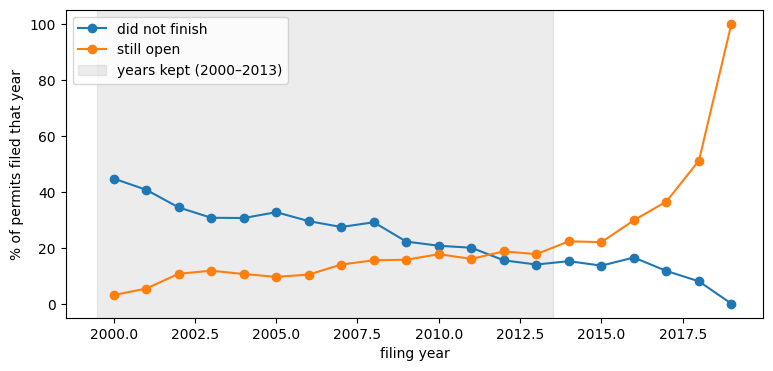

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
year_table[['did not finish', 'still open']].plot(ax=ax, marker='o')
ax.axvspan(1999.5, 2013.5, color='grey', alpha=0.15, label='years kept (2000–2013)')
ax.set_ylabel('% of permits filed that year'); ax.set_xlabel('filing year'); ax.legend()
plt.show()

**Shows:** the share still open climbs from 3% (2000) to 22% (2014) and 51% (2018), so recent years are incomplete and their observed failure rate is biased low. 2019 has a single permit.

**In `permits_data.py`:** `YEAR_MIN, YEAR_MAX = 2000, 2013` keeps the years in which most permits have resolved.

## 6. Leakage columns

In [11]:
resolved = resolved_permits(raw)
leak_cols = ['completed_date', 'issued_date', 'first_construction_document_date',
             'permit_expiration_date', 'revised_cost']
resolved.groupby('y')[leak_cols].apply(lambda d: d.notna().mean().mul(100).round(1)) \
        .rename(index={0: 'completed (y=0)', 1: 'did not finish (y=1)'})

,completed_date,issued_date,first_construction_document_date,permit_expiration_date,revised_cost
y,,,,,
completed (y=0),100.0,100.0,16.9,100.0,96.8
did not finish (y=1),1.2,65.1,8.4,65.2,72.1


**Shows:** `completed_date` is filled for 100% of completed permits and only 1.2% of unfinished ones, so it would almost give the answer away. `issued_date`, expiration date and revised cost are also recorded after filing and differ sharply by outcome.

**In `permits_data.py`:** none of these are in `NUMERIC` or `CATEGORICAL`, so they never reach the model.

## 7. Estimated cost

In [12]:
cost = resolved['estimated_cost']
print(cost.describe().round(0).to_string())
print(f"\n$0 or $1 (placeholder): {(cost <= 1).sum():,} permits ({(cost <= 1).mean():.1%})")
print(f"missing:                {cost.isna().sum():,} permits")

count        60334.0
mean        376036.0
std        3846662.0
min              1.0
25%           8400.0
50%          35000.0
75%         125000.0
max      272000000.0

$0 or $1 (placeholder): 4,136 permits (6.7%)
missing:                1,814 permits


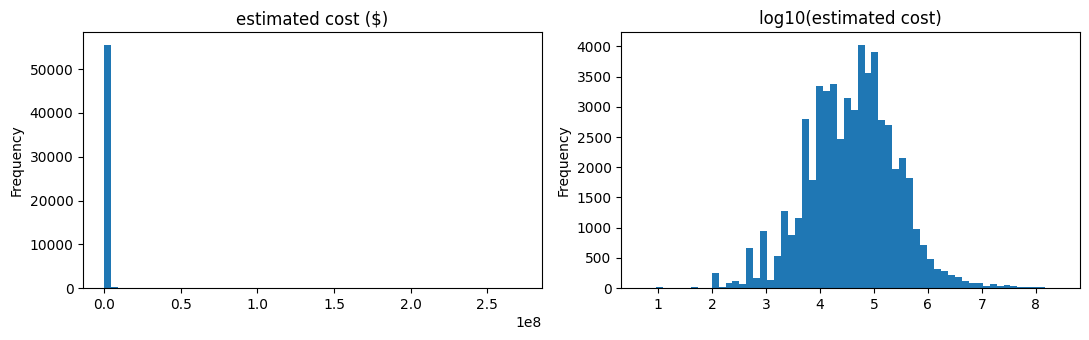

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
cost[cost > 1].plot.hist(bins=60, ax=axes[0], title='estimated cost ($)')
np.log10(cost[cost > 1]).plot.hist(bins=60, ax=axes[1], title='log10(estimated cost)')
plt.tight_layout(); plt.show()

**Shows:** cost ranges from $1 to $272 million. The median is $35,000 but the mean is $376,000, so a few huge projects dominate the raw scale. On a log scale the distribution is roughly bell-shaped. 6.7% of permits list $0 or $1, which is a placeholder rather than a real cost.

**In `permits_data.py`:** `log_estimated_cost = log10(cost)`, with $0/$1 treated as missing and flagged in `cost_is_placeholder`.

## 8. Units and stories

In [14]:
size_cols = ['existing_units', 'proposed_units', 'number_of_existing_stories', 'number_of_proposed_stories', 'plansets']
resolved[size_cols].describe().round(1)

,existing_units,proposed_units,number_of_existing_stories,number_of_proposed_stories,plansets
count,57029.0,58795.0,58287.0,60004.0,62148.0
mean,13.4,14.3,7.7,7.7,1.9
std,78.8,78.9,11.0,10.8,0.7
min,0.0,0.0,0.0,0.0,0.0
25%,0.0,0.0,2.0,2.0,2.0
50%,1.0,1.0,3.0,3.0,2.0
75%,2.0,2.0,6.0,6.0,2.0
max,1907.0,1907.0,222.0,222.0,9.0


In [15]:
featured = add_features(resolved)
for col in ['unit_change', 'story_change']:
    print(col, featured[col].clip(-3, 3).value_counts(normalize=True).sort_index().mul(100).round(1).to_dict())

unit_change {-3.0: 0.2, -2.0: 0.2, -1.0: 1.0, 0.0: 95.6, 1.0: 2.1, 2.0: 0.3, 3.0: 0.6}
story_change {-3.0: 0.0, -2.0: 0.0, -1.0: 0.1, 0.0: 93.8, 0.5: 0.0, 1.0: 5.1, 2.0: 0.7, 2.5: 0.0, 3.0: 0.2}


**Shows:** unit and story counts are heavily skewed (median 1 unit and 3 stories, maximum 1,907 units). Over 93% of permits change neither units nor stories.

**In `permits_data.py`:** `unit_change` and `story_change` record how much a project changes the building, which the raw before/after counts don't show directly.

## 9. Categorical columns

In [16]:
cats = resolved[[c for c in CATEGORICAL if c != 'use_changes']]   # use_changes is built later
cat_summary = pd.DataFrame({
    'levels': cats.nunique(),
    'levels with < 50 permits': cats.apply(lambda s: (s.value_counts() < 50).sum()),
    '% missing': cats.isna().mean().mul(100).round(1),
})
cat_summary

,levels,levels with < 50 permits,% missing
permit_type_definition,4,0,0.0
existing_use,89,53,6.0
proposed_use,89,53,3.2
existing_construction_type_description,5,0,6.5
proposed_construction_type_description,5,0,3.7
structural_notification,1,0,80.1
site_permit,1,0,78.8
fire_only_permit,1,0,99.3
voluntary_soft_story_retrofit,1,0,99.9
neighborhoods_analysis_boundaries,40,3,2.7


In [17]:
# yes/no flags: values as stored
flags = ['structural_notification', 'site_permit', 'fire_only_permit', 'voluntary_soft_story_retrofit']
pd.DataFrame({c: resolved[c].value_counts(dropna=False) for c in flags})

,structural_notification,site_permit,fire_only_permit,voluntary_soft_story_retrofit
NaN,49801,48950,61687,62074
Y,12347,13198,461,74


**Shows:** building use has 89 levels, 53 of them with fewer than 50 permits. The four yes/no flags are stored as `Y` or blank, never `N`.

**In `permits_data.py`:** levels with fewer than 50 permits are pooled into one "infrequent" column (`min_frequency=50`), and blank flags are filled with `N`.

## 10. Duplicate information

In [18]:
# each permit_type code maps to exactly one permit_type_definition
pd.crosstab(raw['permit_type'], raw['permit_type_definition'])

permit_type_definition,additions alterations or repairs,demolitions,new construction,new construction wood frame
permit_type,,,,
1,0,0,995,0
2,0,0,0,4207
3,77878,0,0,0
6,0,3023,0,0


In [19]:
print('construction type code → description, levels per code:',
      raw.groupby('existing_construction_type')['existing_construction_type_description'].nunique().max())
print('zipcodes:', raw['zipcode'].nunique(), '· neighborhoods:', raw['neighborhoods_analysis_boundaries'].nunique())
print('date == filed_date:', (pd.to_datetime(raw['date']) == pd.to_datetime(raw['filed_date']).dt.tz_localize(None)).mean().round(3))

construction type code → description, levels per code: 1
zipcodes: 27 · neighborhoods: 41
date == filed_date: 0.98


**Shows:** each `permit_type` code maps to exactly one `permit_type_definition`, and each construction type code to one description. `zipcode` (27 values) overlaps with neighborhood (41 values). `date` equals `filed_date` for 98% of rows.

**In `permits_data.py`:** only the text labels and neighborhood are kept. The codes, `zipcode` and `date` would repeat the same information.

## 11. Projects filed together

In [20]:
batches = batch_id(resolved)
size = batches.map(batches.value_counts())
print(f'{len(resolved):,} permits in {batches.nunique():,} project batches (same lot, same filing day)')
print(f'permits in a batch of 2 or more: {(size > 1).mean():.1%}')
size.clip(upper=6).value_counts().sort_index().rename(index={6: '6+'}).to_frame('permits').rename_axis('batch size')

62,148 permits in 49,683 project batches (same lot, same filing day)
permits in a batch of 2 or more: 34.4%


,permits
batch size,
1,40782
2,14550
3,2814
4,1484
5,715
6+,1803


In [21]:
# permits in the same batch almost always end the same way
multi = resolved[size > 1].assign(batch=batches[size > 1])
same_outcome = multi.groupby('batch')['y'].nunique().eq(1).mean()
print(f'batches where every permit has the same outcome: {same_outcome:.1%}')

batches where every permit has the same outcome: 93.6%


**Shows:** a third of permits are filed alongside others for the same lot on the same day, and 93.6% of those batches share a single outcome. If a batch were split between train and test, the model would be tested on a project it had already seen.

**In `permits_data.py`:** `batch_id` defines these batches, and both the train/test split and `make_cv()` keep each batch on one side.

## 12. Final dataset

In [22]:
X_train, X_test, y_train, y_test, groups_train, preprocessor = get_permit_data(raw)
groups_test = batch_id(resolved.reset_index(drop=True)).iloc[X_test.index]

pd.DataFrame({
    'rows': [len(X_train), len(X_test)],
    'features': [X_train.shape[1], X_test.shape[1]],
    '% did not finish': [round(y_train.mean() * 100, 1), round(y_test.mean() * 100, 1)],
}, index=['train', 'test'])

,rows,features,% did not finish
train,49676,23,35.7
test,12472,23,36.7


In [23]:
print('batches in both train and test:', len(set(groups_train) & set(groups_test)))
permit_no = resolved.reset_index(drop=True)['permit_number']
split_permits = set(permit_no.iloc[X_train.index]) & set(permit_no.iloc[X_test.index])
print(f'permit numbers with rows in both train and test: {len(split_permits)} ({permit_no.isin(split_permits).mean():.1%} of rows)')
print('numeric features:', len(NUMERIC), '· categorical features:', len(CATEGORICAL))
print('columns after preprocessing:', preprocessor.fit_transform(X_train).shape[1])

batches in both train and test: 0
permit numbers with rows in both train and test: 329 (1.5% of rows)
numeric features: 11 · categorical features: 12


columns after preprocessing: 166


In [24]:
X_train.assign(did_not_finish=y_train).head()

,log_estimated_cost,cost_is_placeholder,plansets,existing_units,proposed_units,unit_change,number_of_existing_stories,number_of_proposed_stories,story_change,filing_year,filing_month,permit_type_definition,existing_use,proposed_use,use_changes,existing_construction_type_description,proposed_construction_type_description,structural_notification,site_permit,fire_only_permit,voluntary_soft_story_retrofit,neighborhoods_analysis_boundaries,supervisor_district,did_not_finish
1,NaN,0,0.0,0.0,NaN,NaN,1.0,NaN,NaN,2000,1,demolitions,storage shed,NaN,NaN,wood frame (5),NaN,N,N,N,N,Sunset/Parkside,4,0
2,5.501059,0,4.0,0.0,0.0,0.0,5.0,5.0,0.0,2000,1,additions alterations or repairs,retail sales,retail sales,no,constr type 2,constr type 2,N,N,N,N,South of Market,6,0
4,4.698970,0,2.0,0.0,0.0,0.0,3.0,3.0,0.0,2000,1,additions alterations or repairs,food/beverage hndlng,food/beverage hndlng,no,constr type 2,constr type 2,N,N,N,N,NaN,NaN,0
5,4.301030,0,2.0,0.0,0.0,0.0,20.0,20.0,0.0,2000,1,additions alterations or repairs,office,office,no,constr type 1,constr type 1,N,N,N,N,NaN,NaN,1
8,5.000000,0,2.0,0.0,0.0,0.0,9.0,9.0,0.0,2000,1,additions alterations or repairs,office,office,no,constr type 1,constr type 1,N,N,N,N,Financial District/South Beach,6,1


**Shows:** 62,148 permits with 23 features, split 80/20 with almost the same failure rate in train (35.7%) and test (36.7%). No batch appears in both sets. A small number of multi-address permits span different lots, so 1.5% of rows share a permit number across the split. Preprocessing turns the 23 features into 166 model columns.

## 13. Imputation vs. dropping rows
A simple reference model (logistic regression with default settings) is scored by grouped 5-fold cross-validated AUC on the training set twice: once with missing values imputed, as in `permits_data.py`, and once with every row that has a missing value dropped.

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from permits_data import make_cv

reference = lambda: Pipeline([('prep', make_preprocessor()), ('model', LogisticRegression(max_iter=2000))])
complete_rows = X_train.notna().all(axis=1)

auc_impute = cross_val_score(reference(), X_train, y_train, groups=groups_train,
                             cv=make_cv(), scoring='roc_auc')
auc_drop = cross_val_score(reference(), X_train[complete_rows], y_train[complete_rows],
                           groups=groups_train[complete_rows], cv=make_cv(), scoring='roc_auc')

pd.DataFrame({
    'training rows used': [len(X_train), int(complete_rows.sum())],
    '% did not finish': [round(y_train.mean() * 100, 1), round(y_train[complete_rows].mean() * 100, 1)],
    'CV ROC AUC (mean)': [round(auc_impute.mean(), 3), round(auc_drop.mean(), 3)],
    'CV ROC AUC (sd)': [round(auc_impute.std(), 3), round(auc_drop.std(), 3)],
}, index=['impute (median / "missing" + indicator)', 'drop rows with any missing value'])

,training rows used,% did not finish,CV ROC AUC (mean),CV ROC AUC (sd)
"impute (median / ""missing"" + indicator)",49676,35.7,0.637,0.006
drop rows with any missing value,39490,35.9,0.637,0.010


**Shows:** dropping incomplete rows throws away 21% of the training permits (49,676 → 39,490) for no gain in AUC (0.637 both ways), and the failure rate barely moves. A model trained on complete rows only would also have no rule for a new application with a blank field.

**In `permits_data.py`:** missing values are imputed, not dropped.